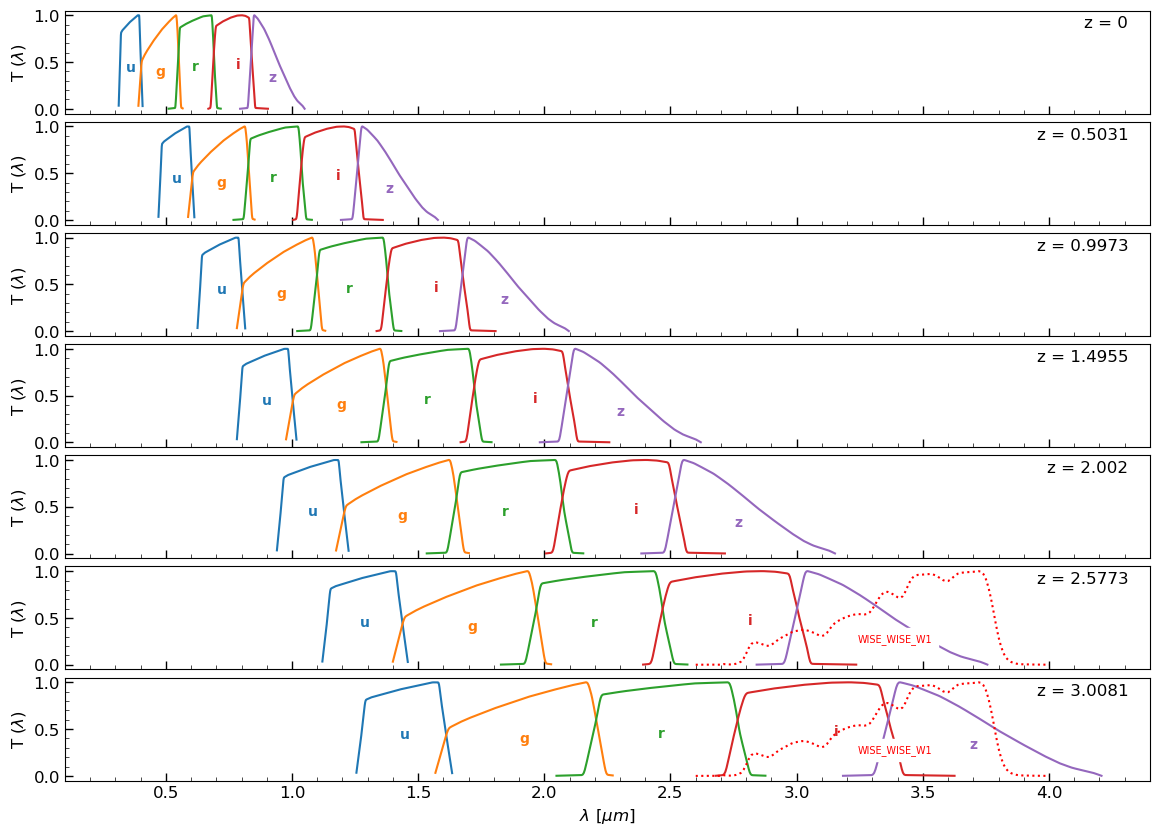

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pts.band as bnd
import astropy.units as u
from astropy.io.votable import parse_single_table

def transmission_curve(filepath, z=0):
    wavelength, rp = np.loadtxt(filepath, unpack=True)
    wavelength *= 1e-4   # 转换单位 μm
    tm = wavelength * rp
    tm /= np.max(tm)
    wavelength *= 1 + z
    return wavelength, tm


def SKIRTband(minWavelength=0.1*u.micron, maxWavelength=4.5*u.micron, nameSegments=""):
    bands = bnd.builtinBands(nameSegments, minWavelength, maxWavelength)
    bands = sorted(bands, key=bnd.BroadBand.pivotWavelength)
    return bands

    
bands = ['u', 'g', 'r', 'i', 'z']
redshift = [0, 0.5031, 0.9973, 1.4955, 2.0020, 2.5773, 3.0081]
# name = ["2MASS"] * len(redshift)
# name = ["Euclid"] * len(redshift)
# name = ["GENERIC"] * len(redshift)
# name = ["HST"] * len(redshift)
# name = ["JWST"] * len(redshift)
# name = ["SPITZER"] * len(redshift)
# name = ["TNG"] * len(redshift)
# name = ["UKIRT"] * len(redshift)
name = ["WISE"] * len(redshift)


fig, axes = plt.subplots(7, 1, figsize=(14, 10), dpi=100, sharex=True, sharey=True)
plt.subplots_adjust(wspace=0.00, hspace=0.08)


for i, z in enumerate(redshift):
    ax = axes[i]
    minv = []
    maxv = []
    
    for band in bands:
        filepath = f'./CSST_SC0-Phot.{band}.dat'
        wavelength, tm = transmission_curve(filepath, z=z)
        minv.append(np.min(wavelength))
        maxv.append(np.max(wavelength))
        
        line, = ax.plot(wavelength, tm)
        color = line.get_color()
        
        # 取曲线中间点
        mid_idx = len(wavelength) // 2
        x_text = wavelength[mid_idx]
        y_text = tm[mid_idx] * 0.4  # 偏上放文字
        
        ax.text(x_text, y_text, band, color=color, fontsize=10, weight='bold',
                ha='center', va='bottom')  # 水平居中，垂直从下向上
        
    bmin, bmax = np.min(minv), np.max(maxv)
    
    SKIRTbands = SKIRTband(nameSegments=name[i])
    colors = ('r','g','b','c','m','y')
    labelpos = 0.25
    colorindex = 0
    for skband in SKIRTbands:
        
        if (bmin < skband.pivotWavelength().to_value(u.micron)) and \
        (skband.pivotWavelength().to_value(u.micron) <= bmax):
            wavelengths, transmissions = skband.transmissionCurve()
            wavelengths = wavelengths.to(u.micron)
            transmissions /= transmissions.max()  # normalize to a maximum of 1

            ax.plot(wavelengths.value, transmissions.value, linestyle=':', color=colors[colorindex])
            ax.text(skband.pivotWavelength().to_value(wavelengths.unit), labelpos, skband.name(),
                     horizontalalignment='center', fontsize='x-small', color=colors[colorindex],backgroundcolor='w')
            colorindex = (colorindex + 1) % len(colors)
        else:
            colorindex = (colorindex + 1) % len(colors)

    
    ax.set_xlabel(r'$\lambda~[\mu m]$', fontsize=12)
    ax.set_ylabel(r'T ($\lambda$)', fontsize=12)
    ax.text(0.98, 0.95, f'z = {z}', transform=ax.transAxes, fontsize=12, ha='right', va='top')
    
    # -------- 调整刻度 --------
    ax.tick_params(axis='both', which='major', labelsize=12, length=6, width=1, direction='in')  # 主刻度
    ax.tick_params(axis='both', which='minor', labelsize=10, length=3, width=0.5, direction='in')    # 小刻度
    ax.minorticks_on()  # 开启小刻度
    ax.set_xlim(0.1, 4.4)

# plt.savefig(f'filter_shifted_{name[0]}.png', dpi=100, bbox_inches='tight')
plt.show()

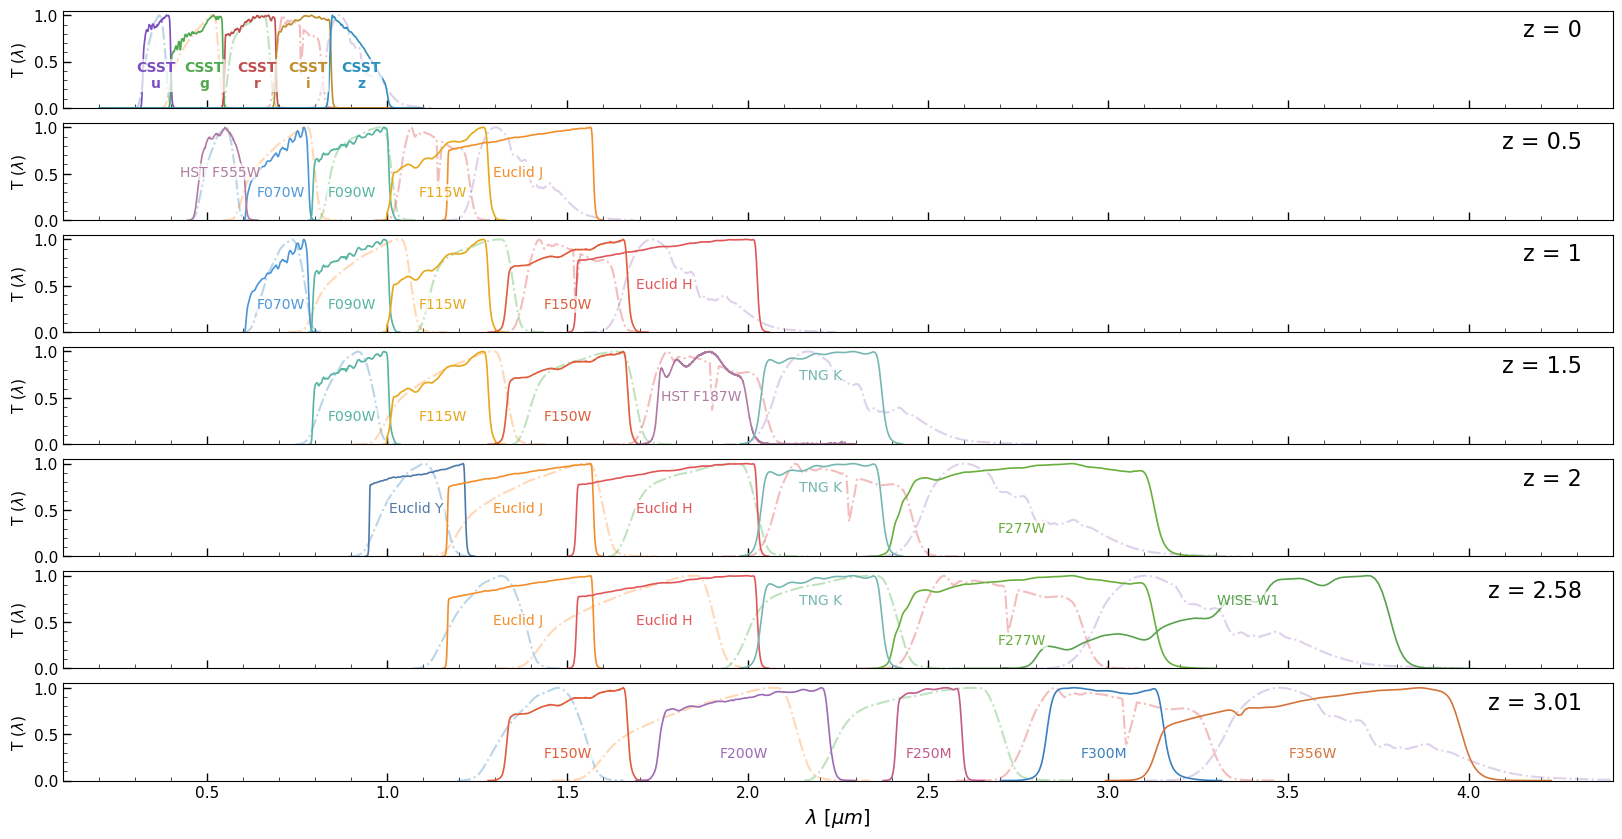

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import pts.band as bnd
import astropy.units as u

# ── 分层高度 ──────────────────────────────────────────────
LABEL_SDSS   = 0.55   # SDSS 标签：曲线峰值 55%
LABEL_ROW1   = 0.30   # 望远镜第一行（JWST）
LABEL_ROW2   = 0.52   # 望远镜第二行（Euclid / HST）
LABEL_ROW3   = 0.74   # 望远镜第三行（WISE / TNG）

# ── 望远镜颜色表 ──────────────────────────────────────────
JWST_COLORS = {
    'JWST_NIRCAM_F070W': '#4C96D7',
    'JWST_NIRCAM_F090W': '#56B4A0',
    'JWST_NIRCAM_F115W': '#E6A817',
    'JWST_NIRCAM_F150W': '#E05C3A',
    'JWST_NIRCAM_F200W': '#9B6BB5',
    'JWST_NIRCAM_F250M': '#C45A8A',
    'JWST_NIRCAM_F277W': '#6AAF3D',
    'JWST_NIRCAM_F300M': '#3A7FBF',
    'JWST_NIRCAM_F356W': '#D4763B',
}
EUCLID_COLORS = {
    'EUCLID_NISP_Y': '#4E79A7',
    'EUCLID_NISP_J': '#F28E2B',
    'EUCLID_NISP_H': '#E15759',
}


def transmission_curve(filepath, z=0):
    wavelength, rp = np.loadtxt(filepath, unpack=True)
    wavelength *= 1e-4
    tm = wavelength * rp
    tm /= np.max(tm)
    wavelength *= 1 + z
    return wavelength, tm


def SKIRTband(minWavelength=0.1*u.micron, maxWavelength=4.5*u.micron, nameSegments=""):
    bands = bnd.builtinBands(nameSegments, minWavelength, maxWavelength)
    bands = sorted(bands, key=bnd.BroadBand.pivotWavelength)
    return bands


def add_label(ax, wavelengths, transmissions, skband, label_text, color, y_row):
    pivot = skband.pivotWavelength().to_value(wavelengths.unit)
    ax.text(pivot, y_row, label_text,
            horizontalalignment='center', verticalalignment='center',
            fontsize=10, color=color, backgroundcolor='w',
            bbox=dict(boxstyle='round,pad=0.1', fc='w', ec='none', alpha=0.7))

def plot_band(ax, wavelengths, transmissions, skband, label_text, color, y_row, idx):
    alpha = 1.0 if idx != 0 else 0.75
    ax.plot(wavelengths.value, transmissions.value, color=color, alpha=alpha, lw=1.2)
    add_label(ax, wavelengths, transmissions, skband, label_text, color, y_row)


# ── 主图 ─────────────────────────────────────────────────
bands    = ['u', 'g', 'r', 'i', 'z']
redshift = [0, 0.5, 1, 1.5, 2, 2.58, 3.01]

fig, axes = plt.subplots(7, 1, figsize=(20, 10), dpi=100, sharex=True, sharey=True)
plt.subplots_adjust(wspace=0.00, hspace=0.15)

# ── SDSS 滤光片 ───────────────────────────────────────────
for i, z in enumerate(redshift):
    ax = axes[i]
    for band in bands:
        filepath = f'./SLOAN_SDSS.{band}.dat'
        wavelength, tm = transmission_curve(filepath, z=z)
        line, = ax.plot(wavelength, tm, linestyle='-.', alpha=0.3)
        color = line.get_color()
        # if z == 0:
        #     peak_idx = np.argmax(tm)
        #     ax.text(wavelength[peak_idx], LABEL_SDSS, band,
        #             color=color, fontsize=10, weight='bold',
        #             ha='center', va='center',
        #             bbox=dict(boxstyle='round,pad=0.1', fc='w', ec='none', alpha=0.7))

    ax.set_ylabel(r'T ($\lambda$)', fontsize=11)
    ax.text(0.98, 0.92, f'z = {z}', transform=ax.transAxes,
            fontsize=16, ha='right', va='top')
    ax.tick_params(axis='both', which='major', labelsize=11, length=6, width=1, direction='in')
    ax.tick_params(axis='both', which='minor', length=3, width=0.5, direction='in')
    ax.minorticks_on()
    ax.set_xlim(0.1, 4.4)
    ax.set_ylim(0, 1.05)

axes[-1].set_xlabel(r'$\lambda~[\mu m]$', fontsize=14)


# ── CSST filters（只画在 z=0 子图）────────────────────────
def transmission_curve_csst(filepath, z=0):
    wavelength, rp = np.loadtxt(filepath, unpack=True)
    wavelength *= 1e-3   # nm → μm
    tm = wavelength * rp
    tm /= np.max(tm)
    wavelength *= 1 + z
    return wavelength, tm

csst_bands = ['u', 'g', 'r', 'i', 'z']
csst_colors = {
    'u': '#7B4FBF',
    'g': '#4FA84F',
    'r': '#BF4F4F',
    'i': '#BF8F2F',
    'z': '#2F8FBF',
}

csst_label_offset = {
    'u': -0.03,
    'g': -0.025,
    'r': -0.03,
    'i': -0.01,
    'z': 0.08,
}

for band in csst_bands:
    filepath = f'/data/suminxian/csst_ms_imaging_throughput/{band}_throughput.txt'
    wavelength, tm = transmission_curve_csst(filepath, z=0)
    color = csst_colors[band]
    axes[0].plot(wavelength, tm, linestyle='-', alpha=1.0, lw=1.2, color=color)
    peak_idx = np.argmax(tm)
    # axes[0].text(wavelength[peak_idx], tm[peak_idx] + csst_label_offset[band], f'CSST {band}',
    #              color=color, fontsize=9, weight='bold',
    #              ha='center', va='bottom',
    #              bbox=dict(boxstyle='round,pad=0.1', fc='w', ec='none', alpha=0.7))
    
    axes[0].text(wavelength[peak_idx] + csst_label_offset[band] , LABEL_SDSS - 0.20, f'CSST\n{band}',
                 color=color, fontsize=10, weight='bold',
                 ha='center', va='center',
                 bbox=dict(boxstyle='round,pad=0.1', fc='w', ec='none', alpha=0.7))


# ── JWST NIRCam ───────────────────────────────────────────
JWST_indices = {
    'JWST_NIRCAM_F070W': [1, 2],
    'JWST_NIRCAM_F090W': [1, 2, 3],
    'JWST_NIRCAM_F115W': [1, 2, 3],
    'JWST_NIRCAM_F150W': [2, 3, 6],
    'JWST_NIRCAM_F200W': [6],
    'JWST_NIRCAM_F250M': [6],
    'JWST_NIRCAM_F277W': [4, 5],
    'JWST_NIRCAM_F300M': [6],
    'JWST_NIRCAM_F356W': [6],
}

for skband in SKIRTband(nameSegments="JWST"):
    name = skband.name()
    if name not in JWST_indices:
        continue
    color = JWST_COLORS.get(name, 'gray')
    short = name.split('_')[-1]
    wavelengths, transmissions = skband.transmissionCurve()
    wavelengths = wavelengths.to(u.micron)
    transmissions /= transmissions.max()
    for idx in JWST_indices[name]:
        plot_band(axes[idx], wavelengths, transmissions, skband, short, color, LABEL_ROW1, idx)


# ── Euclid NISP ───────────────────────────────────────────
EUCLID_indices = {
    'EUCLID_NISP_Y': [4],
    'EUCLID_NISP_J': [1, 4, 5],
    'EUCLID_NISP_H': [2, 4, 5],
}

for skband in SKIRTband(nameSegments="Euclid"):
    name = skband.name()
    if name not in EUCLID_indices:
        continue
    color = EUCLID_COLORS.get(name, 'gray')
    short = name.split('_')[-1]   # Y / J / H
    wavelengths, transmissions = skband.transmissionCurve()
    wavelengths = wavelengths.to(u.micron)
    transmissions /= transmissions.max()
    for idx in EUCLID_indices[name]:
        plot_band(axes[idx], wavelengths, transmissions, skband, f'Euclid {short}', color, LABEL_ROW2, idx)


# ── HST ───────────────────────────────────────────────────
HST_targets = {
    'HST_ACS_WFC_F555W':  ([1],    'F555W'),
    'HST_NICMOS2_F187W':  ([3],    'F187W'),
}
for skband in SKIRTband(nameSegments="HST"):
    name = skband.name()
    if name not in HST_targets:
        continue
    indices, short = HST_targets[name]
    wavelengths, transmissions = skband.transmissionCurve()
    wavelengths = wavelengths.to(u.micron)
    transmissions /= transmissions.max()
    for idx in indices:
        plot_band(axes[idx], wavelengths, transmissions, skband, f'HST {short}', '#B07AA1', LABEL_ROW2, idx)


# ── WISE ─────────────────────────────────────────────────
for skband in SKIRTband(nameSegments="WISE"):
    if skband.name() != 'WISE_WISE_W1':
        continue
    wavelengths, transmissions = skband.transmissionCurve()
    wavelengths = wavelengths.to(u.micron)
    transmissions /= transmissions.max()
    plot_band(axes[5], wavelengths, transmissions, skband, 'WISE W1', '#59A14F', LABEL_ROW3, 5)


# ── TNG NICS ─────────────────────────────────────────────
for skband in SKIRTband(nameSegments="TNG"):
    if skband.name() != 'TNG_NICS_K':
        continue
    wavelengths, transmissions = skband.transmissionCurve()
    wavelengths = wavelengths.to(u.micron)
    transmissions /= transmissions.max()
    for idx in [3, 4, 5]:
        plot_band(axes[idx], wavelengths, transmissions, skband, 'TNG K', '#76B7B2', LABEL_ROW3, idx)

plt.savefig('Filter.png', dpi=300, bbox_inches='tight')
plt.show()

In [1]:
from pts.do.prompt import do
from pts.visual import *

do("list_bands")

   Starting band/list_bands...
   | Band name                     | Pivot wavelength | Effective width
   |-------------------------------|------------------|-----------------
   | 2MASS_2MASS_J                 | 1.2393 micron    | 0.15203 micron
   | 2MASS_2MASS_H                 | 1.6494 micron    | 0.24102 micron
   | 2MASS_2MASS_KS                | 2.1638 micron    | 0.25062 micron
   | ALMA_ALMA_10                  | 349.89 micron    | 48.802 micron
   | ALMA_ALMA_9                   | 456.20 micron    | 67.540 micron
   | ALMA_ALMA_8                   | 689.59 micron    | 137.74 micron
   | ALMA_ALMA_7                   | 937.98 micron    | 272.90 micron
   | ALMA_ALMA_6                   | 1244.4 micron    | 326.23 micron
   | ALMA_ALMA_5                   | 1616.0 micron    | 402.27 micron
   | ALMA_ALMA_4                   | 2100.2 micron    | 552.10 micron
   | ALMA_ALMA_3                   | 3043.4 micron    | 961.88 micron
   | EUCLID_NISP_Y                 | 1.0808 micron 